# Portfolio covariance

The original study is a completed historical analysis. Historical evaluation blocks were reused; they are not fresh holdouts.

Read the saved outputs without executing this notebook. Original code cells, their metadata, execution counts and outputs are preserved. This package supplies selected scientific evidence and context; the code retains its original source environment and frozen-input dependencies. It is not a standalone reproduction environment. See the [notebook index](README.md).


## Research question: Portfolio covariance evaluation

**Question:** Does the thematic factor improve the risk estimate of a collection of holdings?

Both models are refitted on identical complete training dates across all fixed holdings. Predicted variance combines factor covariance and either diagonal or within-industry residual covariance. Future missing quotes omit dates, never holdings.

**Where this fits:** Together with the [company forecasts](company-risk-factor-benchmark.ipynb), this supports a bounded conclusion: extra historical dependence does not establish stable stock-risk forecast value, and portfolio benefits depend on the baseline and holdings. This completes the study; further research is separate.
Run from top to bottom using the project environment and frozen local inputs.
The equations and executable functions are included below, copied from
`src/quiet_index_500/covariance_evaluation.py` when this notebook
is generated. Editing a local function changes this notebook's calculations.
Shared settings, calendar rules, eligibility checks and data loaders remain
package imports. All returns and factors are decimal daily values.

Calculations run in memory without overwriting research CSVs or saved figures.
See `docs/STUDY_SPEC.md` and `docs/TEST_FREEZE.md` for the fixed specification.
Rebuilds preserve these authored cells; lasting method changes also
belong in the source module. The universe, snapshot weights and GICS labels
are retrospective; this is the fixed September 2026 snapshot study.


### Existing method notes

The test specification was frozen in `docs/TEST_FREEZE.md` before this evaluation. Portfolio memberships are fixed at formation from eligible securities, snapshot weights, company size quartiles and the pre-specified SMH-loading median split. Both share classes are retained.

Each portfolio uses common complete training dates across every holding and all seven factor series. Both models are refitted on exactly those dates. The minimum remains 400 observations for the 504-session window or 200 for the 252-session sensitivity. A failed common-date requirement excludes the entire comparison, never a retrospectively selected holding.

Predicted covariance combines sample factor covariance with either diagonal residual covariance or residual covariance within GICS industry groups. Every covariance uses denominator n−1, so differences do not arise from different degrees-of-freedom corrections. Future returns use fixed target weights, with an entire date omitted if any holding or required factor is missing. At least 40 common future dates are required. Only complete factor quarters through 2026 Q2 are evaluated.

QLIKE is realized/predicted − log(realized/predicted) − 1. Negative paired SMH-minus-baseline QLIKE differences favor the extension. Newey–West uncertainty and a moving-block bootstrap use actual quarterly spacing, retaining missing-quarter gaps. These are conditional on estimated loadings and portfolio memberships; the first stage is not resampled. Six confirmation quarters offer limited independent evidence.

The saved membership, date omissions, training coverage, daily realized returns and quarterly evaluations support every summary. Size-dependent files remain under `results/licensed/covariance_evaluation`, with licensed-source provenance. Rebuild using `python -I -m quiet_index_500.covariance_evaluation` in the virtual environment.

The original noncircular block intervals are retained, with circular moving-block intervals added as a reviewer-requested sensitivity. Circular starts give every calendar quarter equal expected inclusion, addressing boundary imbalance in a six-quarter block. Missing quarter slots remain missing under modulo calendar indexing, and counts of rejected all-missing bootstrap draws are saved. This changes uncertainty diagnostics only; portfolios, samples and point estimates remain fixed.


### Method map: preserve the paired comparison

`formation_portfolios` fixes membership and normalized target weights. `predict_portfolio_variances` refits both models on common dates with covariance denominator n−1. `realized_portfolio_variance` retains target weights when evaluating future common dates. `variance_losses` measures QLIKE = realized/predicted − log(realized/predicted) − 1.


In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image, display

from quiet_index_500 import settings
from quiet_index_500.foundation import calendar, eligibility, loader

In [2]:
standard_factor_names = ('mkt_rf', 'smb', 'hml', 'rmw', 'cma', 'mom')

## 1. Formation-fixed portfolios

Select factor-eligible securities before observing the following quarter.
Retain both share classes. Snapshot, size-quartile and high/low-SMH portfolios
normalize snapshot weights over their fixed members; the equal portfolio uses
equal security weights. Size quartiles are assigned by issuer and mapped to
each class. High SMH means strictly above the formation median; ties go low.
These fixed target weights imply daily rebalancing, without buy-and-hold drift.


In [3]:
def formation_portfolios(exposures, identifiers, size_rows):
    """Return predetermined portfolio membership and normalized fixed target weights.

    Securities are factor-eligible at formation; both share classes are retained.
    Size membership is assigned once per issuer using the saved company quartile,
    then mapped to all its eligible share classes. Size portfolios and SMH halves
    are snapshot-weighted; the equal portfolio is equal-security-weighted.
    """
    eligible = exposures.loc[exposures["eligible"]].set_index("ticker")
    members = identifiers.loc[eligible.index].copy()
    members["smh_loading"] = eligible["m4_smh_excess"]
    quartile_by_cik = size_rows.set_index("cik")["size_quartile"]
    if not quartile_by_cik.index.is_unique:
        raise ValueError("size rows must contain one formation and one row per issuer")
    members["size_quartile"] = members["cik"].map(quartile_by_cik)
    median_loading = members["smh_loading"].median()
    assignments = {"snapshot": members.index, "equal": members.index,
                   "high_smh": members.index[members["smh_loading"] > median_loading],
                   "low_smh": members.index[members["smh_loading"] <= median_loading]}
    assignments.update({f"size_q{quartile}": members.index[members["size_quartile"] == quartile] for quartile in range(1, 5)})
    rows = []
    for portfolio, tickers in assignments.items():
        selected = members.loc[tickers]
        unnormalized = pd.Series(1.0, index=tickers) if portfolio == "equal" else selected["snapshot_weight"]
        weights = unnormalized / unnormalized.sum()
        for ticker in tickers:
            rows.append({"portfolio": portfolio, "ticker": ticker, "cik": int(selected.at[ticker, "cik"]),
                         "weight": float(weights[ticker]), "snapshot_weight": float(selected.at[ticker, "snapshot_weight"]),
                         "gics_industry_group_code": selected.at[ticker, "gics_industry_group_code"],
                         "formation_smh_loading": float(selected.at[ticker, "smh_loading"]),
                         "smh_split_median": float(median_loading) if portfolio.endswith("smh") else np.nan,
                         "licensed_size_dependency": portfolio.startswith("size_")})
    return pd.DataFrame(rows)

## 2. Portfolio variance forecast equation

Refit M3 (FF5 plus momentum) and M4 (M3 plus SMH) on one portfolio-specific
training mask: all fixed holdings and all seven factors must be observed.
Use 504/400 and 252/200 windows/minimum dates. No holding is dropped to improve
coverage. These refits differ from the security-level [factor-exposure measurement fits](../reproduction/factor-risk/notebooks/04_factor_exposures.ipynb).

$$\boxed{\widehat v^{(m,R)}_{p,t+1\mid t}
=252\,w_{p,t}^{\top}
[\widehat B_{m,t}\widehat\Sigma_{f,m,t}\widehat B_{m,t}^{\top}
+\widehat\Sigma_{\epsilon,m,t}^{(R)}]w_{p,t}}.$$

$B$ contains security factor slopes. The factor term is equivalently the sample
variance of the fitted portfolio return; a constant intercept does not affect it.
Both factor and residual sample covariance use denominator n-1.
Residual treatment $R$ is either diagonal or within-industry-group blocks:
$$w^\top\widehat\Sigma_\epsilon^{diag}w
=\sum_i w_i^2\operatorname{Var}(\widehat\epsilon_i),\qquad
w^\top\widehat\Sigma_\epsilon^{block}w
=\sum_g\operatorname{Var}\left(\sum_{i\in g}w_i\widehat\epsilon_i\right).$$

`predict_portfolio_variances` implements this equation. The next-quarter realized
target is $v_{p,t+1}=252\operatorname{Var}_{d\in Q(t+1)}
(\sum_i w_{i,t}(r_{i,d}-r_{f,d}))$, requiring at least 40 common dates and
a complete factor-covered quarter. Missing holdings/factors omit the entire date;
weights are never renormalized around a missing quote. Omissions are recorded.


In [4]:
def predict_portfolio_variances(training_excess_returns, training_factors, weights, industry_groups, minimum_observations):
    """Fit the two models on one common matrix and return annualized predictions.

    The caller supplies fixed weights indexed by ticker. Missing dates are omitted
    jointly; no holding is removed. The result contains the exact training dates,
    training omission diagnostics and predictions for both residual treatments.
    """
    stocks = training_excess_returns.reindex(columns=weights.index)
    factor_names = [*standard_factor_names, "smh_excess"]
    factors = training_factors.reindex(stocks.index)[factor_names]
    common = stocks.notna().all(axis=1) & factors.notna().all(axis=1)
    if not np.isclose(weights.sum(), 1.0, atol=1e-12):
        raise ValueError("fixed portfolio weights must sum to one")
    omissions = pd.DataFrame({"date": stocks.index[~common],
                              "missing_security_count": stocks.isna().sum(axis=1).loc[~common].to_numpy(),
                              "missing_factor_count": factors.isna().sum(axis=1).loc[~common].to_numpy()})
    observation_dates = stocks.index[common]
    if len(observation_dates) < minimum_observations:
        return {"eligible": False, "reason": "insufficient_common_training_dates", "observations": len(observation_dates),
                "observation_dates": observation_dates, "omissions": omissions, "predictions": pd.DataFrame()}
    response = stocks.loc[common].to_numpy(dtype=float)
    ordered_weights = weights.to_numpy(dtype=float)
    industry = industry_groups.reindex(weights.index)
    if industry.isna().any():
        raise ValueError("industry labels required for the fixed holdings")
    predictions = []
    for model, names in (("ff5_mom", standard_factor_names), ("ff5_mom_smh", factor_names)):
        design = np.column_stack([np.ones(len(response)), factors.loc[common, list(names)].to_numpy(dtype=float)])
        coefficients, _, rank, _ = np.linalg.lstsq(design, response, rcond=None)
        if rank != design.shape[1]:
            raise ValueError("rank-deficient covariance factor design")
        fitted = design @ coefficients
        residual = response - fitted
        fitted_portfolio = fitted @ ordered_weights
        factor_variance = np.var(fitted_portfolio, ddof=1)
        diagonal_residual_variance = float((ordered_weights ** 2) @ np.var(residual, axis=0, ddof=1))
        industry_residual_variance = 0.0
        for group in industry.unique():
            selection = industry.to_numpy() == group
            weighted_group_residual = residual[:, selection] @ ordered_weights[selection]
            industry_residual_variance += float(np.var(weighted_group_residual, ddof=1))
        for residual_treatment, residual_variance in (("diagonal", diagonal_residual_variance), ("industry_block", industry_residual_variance)):
            predictions.append({"model": model, "residual_treatment": residual_treatment,
                                "predicted_variance": (factor_variance + residual_variance) * settings.annualisation_sessions,
                                "factor_variance": factor_variance * settings.annualisation_sessions,
                                "residual_variance": residual_variance * settings.annualisation_sessions,
                                "training_observations": len(response), "factor_design_rank": rank,
                                "covariance_denominator": len(response) - 1})
    return {"eligible": True, "reason": "eligible", "observations": len(response), "observation_dates": observation_dates,
            "omissions": omissions, "predictions": pd.DataFrame(predictions)}

def realized_portfolio_variance(future_excess_returns, future_factors, weights, minimum_observations):
    """Realized annualized variance with fixed weights and no missing-quote reweighting."""
    stocks = future_excess_returns.reindex(columns=weights.index)
    factors = future_factors.reindex(stocks.index)[[*standard_factor_names, "smh_excess"]]
    common = stocks.notna().all(axis=1) & factors.notna().all(axis=1)
    omissions = pd.DataFrame({"date": stocks.index[~common],
                              "missing_security_count": stocks.isna().sum(axis=1).loc[~common].to_numpy(),
                              "missing_factor_count": factors.isna().sum(axis=1).loc[~common].to_numpy()})
    portfolio_returns = stocks.loc[common] @ weights
    eligible = len(portfolio_returns) >= minimum_observations
    return {"eligible": eligible, "reason": "eligible" if eligible else "insufficient_common_future_dates",
            "observations": len(portfolio_returns),
            "realized_variance": float(portfolio_returns.var(ddof=1) * settings.annualisation_sessions) if eligible else np.nan,
            "returns": portfolio_returns, "omissions": omissions}

**Saved variance-level illustration.** Compare both model forecasts with following-quarter realized portfolio variance, separately for diagonal and industry-block residual covariance. Units are annualized variance, not volatility. Gaps retain failed common-history samples; shading marks confirmation. Source: the existing publication calibration figure for the snapshot-weighted portfolio.


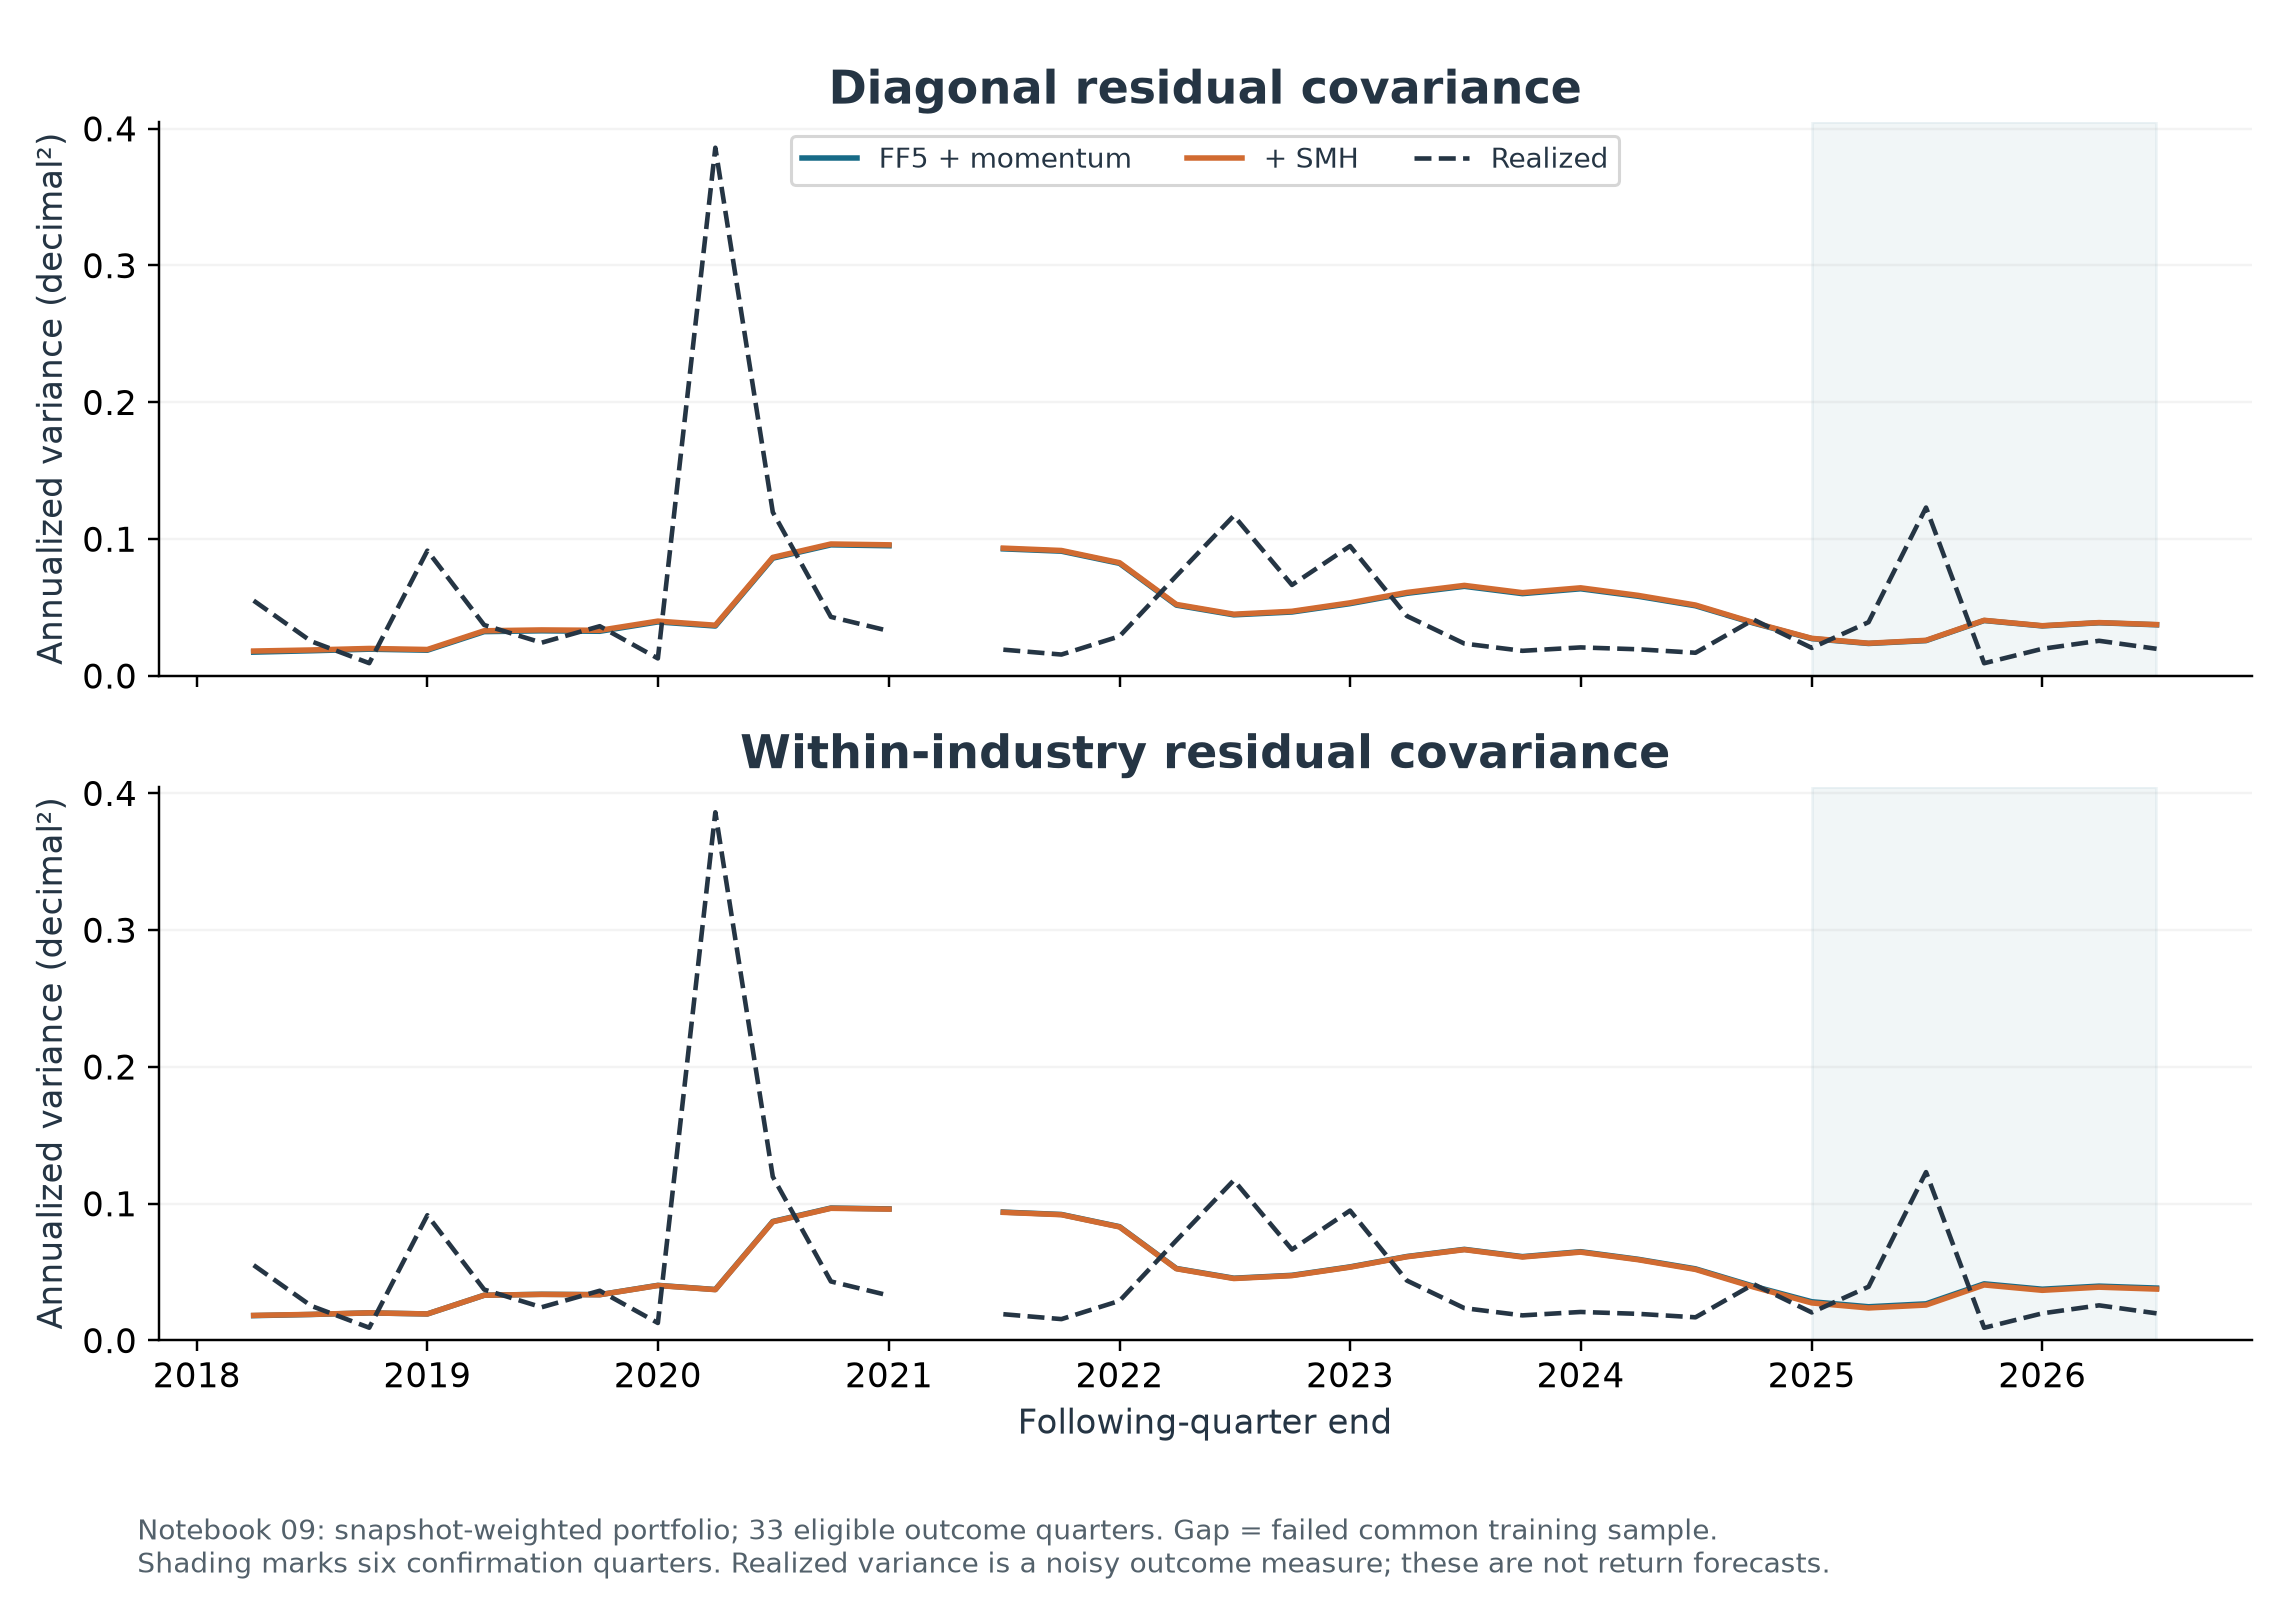

In [5]:
display(Image(filename=str(settings.repository_root_folder / 'results/publication/06_variance_calibration.png'), width=1000))

## 3. Variance losses and paired quarter uncertainty

Let $p$ be predicted variance and $r$ realized variance. Diagnostics are
bias ratio $p/r$, log ratio $\log(p/r)$, absolute log ratio, and
$$\operatorname{QLIKE}(p,r)=r/p-\log(r/p)-1.$$

Lower QLIKE and absolute log ratio are better. Paired differences are
**SMH minus baseline**, so negative loss differences favor SMH. Quarter-level
Newey-West and moving/circular block intervals condition on fitted loadings and
fixed memberships. Missing calendar quarters retain their lag positions.
Six confirmation quarters offer limited independent evidence.


In [6]:
def variance_losses(predicted_variance, realized_variance):
    """Scale-free variance diagnostics; QLIKE is r/p-log(r/p)-1, lower is better."""
    if predicted_variance <= 0 or realized_variance <= 0:
        raise ValueError("variance loss requires positive predicted and realized variance")
    bias_ratio = predicted_variance / realized_variance
    inverse_ratio = 1 / bias_ratio
    log_ratio = float(np.log(bias_ratio))
    return {"bias_ratio": bias_ratio, "log_variance_ratio": log_ratio,
            "absolute_log_variance_ratio": abs(log_ratio),
            "qlike": inverse_ratio - np.log(inverse_ratio) - 1,
            "underestimated": predicted_variance < realized_variance}

def _block_resample_indices(starts, block_length, calendar_count, circular=False):
    indices = (starts[:, :, None] + np.arange(block_length)).reshape(len(starts), -1)[:, :calendar_count]
    return indices % calendar_count if circular else indices

def _valid_resample_means(dense_values, indices):
    samples = dense_values[indices]
    finite_counts = np.isfinite(samples).sum(axis=1)
    accepted = finite_counts > 0
    means = np.nansum(samples[accepted], axis=1) / finite_counts[accepted]
    if len(means) == 0:
        raise ValueError("all bootstrap samples contain only missing quarters")
    return means, int((~accepted).sum())

def quarterly_mean_uncertainty(values, *, quarters=None, replications=settings.bootstrap_replications):
    """Quarter-level NW and moving-block mean uncertainty, conditional on estimates.

    Resampling units are whole quarters, preserving common shocks inside each
    portfolio. The bootstrap does not reestimate first-stage loadings or memberships.
    """
    values = np.asarray(values, dtype=float)
    if not np.isfinite(values).all() or len(values) == 0:
        raise ValueError("nonempty finite quarterly differences required")
    count = len(values)
    mean = float(values.mean())
    if quarters is None:
        dense_values = values
    else:
        periods = pd.PeriodIndex(pd.to_datetime(quarters), freq="Q")
        if not periods.is_unique or len(periods) != count:
            raise ValueError("one value per unique calendar quarter required")
        dense_values = pd.Series(values, index=periods).reindex(pd.period_range(periods.min(), periods.max(), freq="Q")).to_numpy()
    calendar_count = len(dense_values)
    centered = np.where(np.isfinite(dense_values), dense_values - mean, 0.0)  # missing quarters contribute no pair, never collapse a lag
    lag_count = min(settings.newey_west_lags, calendar_count - 1)
    long_run_variance = float(centered @ centered / count)
    for lag in range(1, lag_count + 1):
        autocovariance = float(centered[lag:] @ centered[:-lag] / count)
        long_run_variance += 2 * (1 - lag / (lag_count + 1)) * autocovariance
    standard_error = np.sqrt(max(long_run_variance, 0) / count)
    block_length = min(settings.bootstrap_block_length, calendar_count)
    generator = np.random.default_rng(settings.bootstrap_random_seed)
    blocks_needed = int(np.ceil(calendar_count / block_length))
    starts = generator.integers(0, calendar_count - block_length + 1, size=(replications, blocks_needed))
    indices = _block_resample_indices(starts, block_length, calendar_count)
    bootstrap_means, all_missing = _valid_resample_means(dense_values, indices)
    circular_generator = np.random.default_rng(settings.bootstrap_random_seed)
    circular_starts = circular_generator.integers(0, calendar_count, size=(replications, blocks_needed))
    circular_indices = _block_resample_indices(circular_starts, block_length, calendar_count, circular=True)
    circular_means, circular_all_missing = _valid_resample_means(dense_values, circular_indices)
    return {"quarters": count, "calendar_quarters": calendar_count, "missing_quarters": calendar_count - count,
            "mean_difference": mean, "newey_west_standard_error": standard_error,
            "newey_west_lags": lag_count, "normal_interval_low": mean - 1.96 * standard_error,
            "normal_interval_high": mean + 1.96 * standard_error,
            "bootstrap_interval_low": float(np.quantile(bootstrap_means, 0.025)),
            "bootstrap_interval_high": float(np.quantile(bootstrap_means, 0.975)),
            "bootstrap_block_length": block_length, "bootstrap_replications": replications,
            "bootstrap_valid_replications": len(bootstrap_means), "bootstrap_all_missing_replications": all_missing,
            "circular_bootstrap_interval_low": float(np.quantile(circular_means, 0.025)),
            "circular_bootstrap_interval_high": float(np.quantile(circular_means, 0.975)),
            "circular_bootstrap_valid_replications": len(circular_means),
            "circular_bootstrap_all_missing_replications": circular_all_missing}

def summarize_covariance_results(evaluations):
    """Period summaries and paired SMH-minus-baseline loss differences by portfolio."""
    valid = evaluations.loc[evaluations["evaluation_eligible"]].copy()
    summaries, differences, inference = [], [], []
    group_columns = ["window_sessions", "portfolio", "residual_treatment"]
    for keys, group in valid.groupby(group_columns, sort=True):
        identity = dict(zip(group_columns, keys))
        for block in ("all", "development", "validation", "confirmation"):
            period = group if block == "all" else group.loc[group["outcome_block"] == block]
            if period.empty:
                continue
            for model, model_rows in period.groupby("model"):
                summaries.append({**identity, "outcome_block": block, "model": model, "quarters": len(model_rows),
                                  "mean_bias_ratio": model_rows["bias_ratio"].mean(),
                                  "mean_log_variance_ratio": model_rows["log_variance_ratio"].mean(),
                                  "mean_absolute_log_variance_ratio": model_rows["absolute_log_variance_ratio"].mean(),
                                  "mean_qlike": model_rows["qlike"].mean(),
                                  "share_underestimated": model_rows["underestimated"].mean(),
                                  "mean_training_observations": model_rows["training_observations"].mean(),
                                  "mean_future_observations": model_rows["future_observations"].mean()})
            for metric in ("qlike", "absolute_log_variance_ratio", "log_variance_ratio"):
                paired = period.pivot(index="formation_date", columns="model", values=metric).dropna()
                if paired.empty:
                    continue
                differences_by_date = paired["ff5_mom_smh"] - paired["ff5_mom"]
                if block == "all":
                    for date, difference in differences_by_date.items():
                        differences.append({**identity, "formation_date": date, "metric": metric, "smh_minus_baseline": difference})
                inference.append({**identity, "outcome_block": block, "metric": metric,
                                  **quarterly_mean_uncertainty(differences_by_date.to_numpy(), quarters=differences_by_date.index)})
    return {"period_summary": pd.DataFrame(summaries), "paired_quarterly_differences": pd.DataFrame(differences),
            "paired_inference": pd.DataFrame(inference)}

### Worked example: variance underestimation and QLIKE

Illustrative inputs are separate from study data. The saved short example to connect the method to its numerical output.


In [7]:
# Predict 20% annual volatility (variance .04), realize variance .08.
variance_losses(predicted_variance=.04, realized_variance=.08)

{'bias_ratio': 0.5,
 'log_variance_ratio': -0.6931471805599453,
 'absolute_log_variance_ratio': 0.6931471805599453,
 'qlike': np.float64(0.3068528194400546),
 'underestimated': True}

**Saved loss-comparison illustration.** Bars are 100 × (1 − mean augmented QLIKE / mean baseline QLIKE) in the six confirmation quarters; positive is better. This ratio of period mean losses differs from the [company forecast comparison](company-risk-factor-benchmark.ipynb)'s mean quarterly percentage improvements and from the raw paired loss differences used for inference. Portfolios overlap, and the bars are point estimates. Source: the existing publication portfolio comparison.


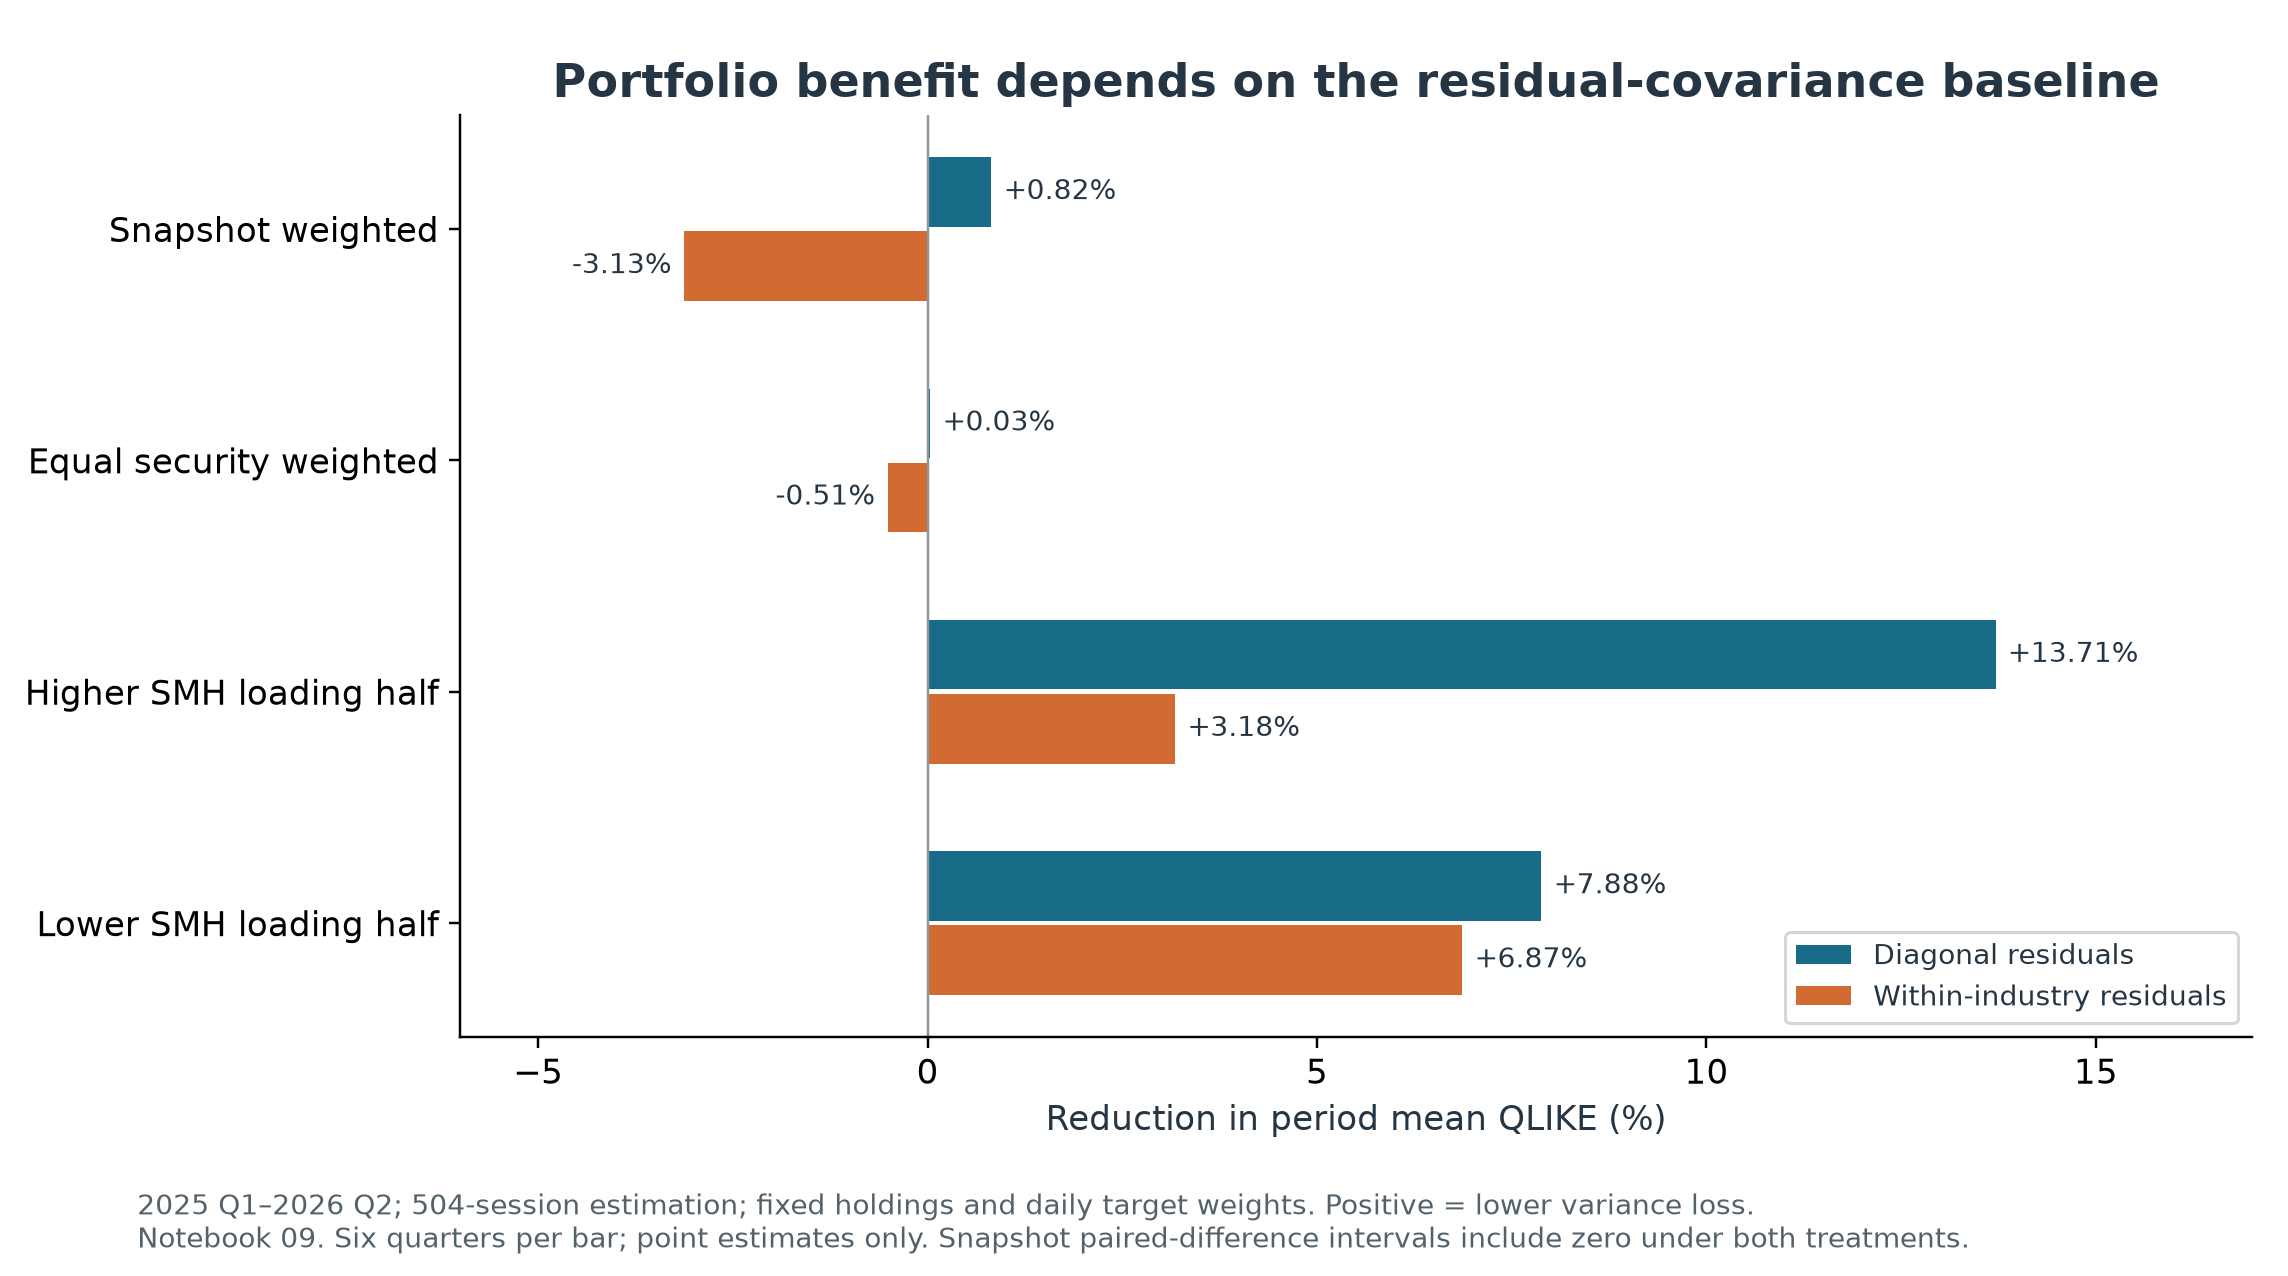

In [8]:
display(Image(filename=str(settings.repository_root_folder / 'results/publication/05_portfolio_comparison.png'), width=1000))

## 4. Saved computation for both windows and fixed portfolios

The calculation below uses the local functions above and frozen upstream size
and exposure tables. It returns membership, omission, training, realized-return,
evaluation and inference tables without saving files. Size portfolios retain
their FMP-derived provenance. This computation can take several minutes.


In [9]:
def build_covariance_tables():
    """Compute both windows' frozen portfolio comparisons without writing outputs."""
    freeze_path = settings.repository_root_folder / "docs/TEST_FREEZE.md"
    if not freeze_path.exists():
        raise RuntimeError("freeze the tests before evaluating outcomes")
    identifiers = loader.load_identifiers()
    price_panels = loader.load_price_panels()
    daily_returns = loader.daily_simple_returns_from_prices(price_panels.adjusted_close, price_panels.quarantined_returns)
    factors = loader.load_factors()
    excess_returns = loader.excess_returns(daily_returns, factors["rf"])
    common_factors = factors[list(standard_factor_names)].join(loader.load_smh_excess_returns().rename("smh_excess"))
    size_path = settings.licensed_results_folder / "size_liquidity/size.csv"
    size = pd.read_csv(size_path, parse_dates=["formation_date"])
    sessions = daily_returns.index
    factor_cutoff = loader.factor_data_last_date()
    evaluation_rows, membership_rows, omission_rows, realized_rows, training_rows = [], [], [], [], []
    for window_sessions, minimum in ((settings.main_window_sessions, settings.main_window_minimum_observations),
                                     (settings.sensitivity_window_sessions, settings.sensitivity_window_minimum_observations)):
        exposure_path = settings.results_folder / "factor_exposures" / f"exposures_{window_sessions}.csv"
        exposures = pd.read_csv(exposure_path, parse_dates=["formation_date"])
        for formation_date, formation_exposures in exposures.groupby("formation_date", sort=True):
            cutoff = calendar.measurement_cutoff(formation_date, factor_cutoff)
            training_window = calendar.estimation_window(sessions, cutoff, window_sessions)
            future_window = calendar.following_quarter_sessions(sessions, formation_date)
            complete_outcome = calendar.following_quarter_complete(formation_date, factor_cutoff)
            memberships = formation_portfolios(formation_exposures, identifiers, size.loc[size["formation_date"] == formation_date])
            memberships["formation_date"] = formation_date
            memberships["window_sessions"] = window_sessions
            membership_rows.append(memberships)
            for portfolio, member_rows in memberships.groupby("portfolio", sort=True):
                weights = member_rows.set_index("ticker")["weight"]
                industry = identifiers["gics_industry_group_code"]
                common = {"formation_date": formation_date, "measurement_cutoff": cutoff, "window_sessions": window_sessions,
                          "portfolio": portfolio, "holdings": len(weights), "issuers": member_rows["cik"].nunique(),
                          "represented_snapshot_weight": member_rows["snapshot_weight"].sum(),
                          "outcome_quarter": str(calendar.outcome_quarter(formation_date)), "outcome_block": calendar.outcome_block(formation_date),
                          "outcome_complete": complete_outcome, "licensed_size_dependency": portfolio.startswith("size_")}
                predicted = predict_portfolio_variances(excess_returns.reindex(training_window), common_factors, weights, industry, minimum)
                training_rows.append({**common, "training_window_sessions": len(training_window), "training_observations": predicted["observations"],
                                      "training_omitted_dates": len(predicted["omissions"]), "training_eligible": predicted["eligible"],
                                      "training_reason": predicted["reason"], "minimum_observations": minimum,
                                      "window_first_session": training_window.min(), "window_last_session": training_window.max()})
                for row in predicted["omissions"].to_dict("records"):
                    omission_rows.append({**common, "phase": "training", **row})
                future = realized_portfolio_variance(excess_returns.reindex(future_window), common_factors, weights,
                                                     settings.forward_outcome_minimum_valid_days) if complete_outcome else None
                if future is not None:
                    for row in future["omissions"].to_dict("records"):
                        omission_rows.append({**common, "phase": "future", **row})
                    for date, value in future["returns"].items():
                        realized_rows.append({**common, "date": date, "portfolio_excess_return": value})
                evaluation_eligible = predicted["eligible"] and complete_outcome and future["eligible"]
                reason = (predicted["reason"] if not predicted["eligible"] else "incomplete_factor_outcome" if not complete_outcome
                          else future["reason"])
                prediction_rows = predicted["predictions"].to_dict("records") if predicted["eligible"] else [
                    {"model": model, "residual_treatment": treatment, "predicted_variance": np.nan,
                     "training_observations": predicted["observations"]}
                    for model in ("ff5_mom", "ff5_mom_smh") for treatment in ("diagonal", "industry_block")]
                for prediction in prediction_rows:
                    row = {**common, **prediction, "evaluation_eligible": bool(evaluation_eligible), "evaluation_reason": reason,
                           "training_omitted_dates": len(predicted["omissions"]), "future_sessions": len(future_window),
                           "future_observations": future["observations"] if future is not None else 0,
                           "future_omitted_dates": len(future["omissions"]) if future is not None else len(future_window),
                           "realized_variance": future["realized_variance"] if future is not None else np.nan}
                    if evaluation_eligible:
                        row.update(variance_losses(row["predicted_variance"], row["realized_variance"]))
                    evaluation_rows.append(row)
            print(f"covariance: {window_sessions} sessions, formation {formation_date.date()}", flush=True)
    tables = {"quarterly_evaluation": pd.DataFrame(evaluation_rows), "membership": pd.concat(membership_rows, ignore_index=True),
              "date_omissions": pd.DataFrame(omission_rows), "realized_daily_returns": pd.DataFrame(realized_rows),
              "training_coverage": pd.DataFrame(training_rows)}
    tables.update(summarize_covariance_results(tables["quarterly_evaluation"]))
    return tables

In [10]:
from contextlib import redirect_stdout
from io import StringIO
with redirect_stdout(StringIO()):
    tables = build_covariance_tables()
summary = tables["period_summary"]
display(summary.loc[summary.window_sessions.eq(settings.main_window_sessions) & summary.portfolio.eq("snapshot")])
display(summary.loc[summary.window_sessions.eq(settings.main_window_sessions) & summary.outcome_block.eq("confirmation")])

,window_sessions,portfolio,residual_treatment,outcome_block,model,quarters,mean_bias_ratio,mean_log_variance_ratio,mean_absolute_log_variance_ratio,mean_qlike,share_underestimated,mean_training_observations,mean_future_observations
240,504,snapshot,diagonal,all,ff5_mom,33,1.838263,0.222313,0.851875,0.634796,0.424242,452.454545,62.303030
241,504,snapshot,diagonal,all,ff5_mom_smh,33,1.856734,0.235110,0.850255,0.624358,0.424242,452.454545,62.303030
242,504,snapshot,diagonal,development,ff5_mom,19,1.652682,0.009448,0.878328,0.799983,0.578947,445.105263,62.263158
243,504,snapshot,diagonal,development,ff5_mom_smh,19,1.671619,0.025567,0.872076,0.781144,0.578947,445.105263,62.263158
244,504,snapshot,diagonal,validation,ff5_mom,8,2.351076,0.760380,0.776159,0.284815,0.125000,463.375000,62.750000
245,504,snapshot,diagonal,validation,ff5_mom_smh,8,2.376635,0.770844,0.784357,0.290052,0.125000,463.375000,62.750000
246,504,snapshot,diagonal,confirmation,ff5_mom,6,1.742183,0.178962,0.869059,0.578344,0.333333,461.166667,61.833333
247,504,snapshot,diagonal,confirmation,ff5_mom_smh,6,1.749730,0.184352,0.869022,0.573607,0.333333,461.166667,61.833333
248,504,snapshot,industry_block,all,ff5_mom,33,1.873210,0.244631,0.852181,0.620985,0.424242,452.454545,62.303030
249,504,snapshot,industry_block,all,ff5_mom_smh,33,1.860369,0.237060,0.850327,0.623517,0.424242,452.454545,62.303030


,window_sessions,portfolio,residual_treatment,outcome_block,model,quarters,mean_bias_ratio,mean_log_variance_ratio,mean_absolute_log_variance_ratio,mean_qlike,share_underestimated,mean_training_observations,mean_future_observations
134,504,equal,diagonal,confirmation,ff5_mom,6,1.324799,0.010103,0.716647,0.621916,0.333333,461.166667,61.833333
135,504,equal,diagonal,confirmation,ff5_mom_smh,6,1.327195,0.011773,0.717696,0.621700,0.333333,461.166667,61.833333
142,504,equal,industry_block,confirmation,ff5_mom,6,1.356713,0.035987,0.721364,0.600486,0.333333,461.166667,61.833333
143,504,equal,industry_block,confirmation,ff5_mom_smh,6,1.354197,0.033620,0.721797,0.603565,0.333333,461.166667,61.833333
150,504,high_smh,diagonal,confirmation,ff5_mom,6,1.337715,-0.028684,0.680724,0.424129,0.333333,493.500000,62.166667
151,504,high_smh,diagonal,confirmation,ff5_mom_smh,6,1.427214,0.051626,0.678639,0.365974,0.333333,493.500000,62.166667
158,504,high_smh,industry_block,confirmation,ff5_mom,6,1.394884,0.021787,0.682515,0.388255,0.333333,493.500000,62.166667
159,504,high_smh,industry_block,confirmation,ff5_mom_smh,6,1.412878,0.038778,0.680561,0.375916,0.333333,493.500000,62.166667
166,504,low_smh,diagonal,confirmation,ff5_mom,6,1.300023,-0.014386,0.718289,0.676821,0.333333,461.500000,61.833333
167,504,low_smh,diagonal,confirmation,ff5_mom_smh,6,1.397616,0.060610,0.741128,0.623478,0.333333,461.500000,61.833333


## 5. Inspect the forecast decomposition and paired evidence


In [11]:
selected_window = settings.main_window_sessions
selected_portfolio = "snapshot"
evaluation = tables["quarterly_evaluation"]
selected_formation = evaluation.loc[evaluation.evaluation_eligible, "formation_date"].max()
display(evaluation.loc[
    evaluation.window_sessions.eq(selected_window)
    & evaluation.portfolio.eq(selected_portfolio)
    & evaluation.formation_date.eq(selected_formation),
    ["formation_date", "model", "residual_treatment", "factor_variance", "residual_variance",
     "predicted_variance", "realized_variance", "bias_ratio", "qlike",
     "training_observations", "future_observations"]
])
display(tables["paired_inference"].loc[
    lambda rows: rows.window_sessions.eq(selected_window)
    & rows.portfolio.eq(selected_portfolio) & rows.outcome_block.eq("confirmation")
])
display(tables["training_coverage"].tail(8))

,formation_date,model,residual_treatment,factor_variance,residual_variance,predicted_variance,realized_variance,bias_ratio,qlike,training_observations,future_observations
1084,2026-03-31,ff5_mom,diagonal,0.035919,0.001404,0.037323,0.019757,1.889111,0.165456,501,62
1085,2026-03-31,ff5_mom,industry_block,0.035919,0.002332,0.038251,0.019757,1.936076,0.177172,501,62
1086,2026-03-31,ff5_mom_smh,diagonal,0.036301,0.001171,0.037472,0.019757,1.896626,0.167329,501,62
1087,2026-03-31,ff5_mom_smh,industry_block,0.036301,0.001188,0.037489,0.019757,1.897515,0.167550,501,62


,window_sessions,portfolio,residual_treatment,outcome_block,metric,quarters,calendar_quarters,missing_quarters,mean_difference,newey_west_standard_error,...,bootstrap_interval_low,bootstrap_interval_high,bootstrap_block_length,bootstrap_replications,bootstrap_valid_replications,bootstrap_all_missing_replications,circular_bootstrap_interval_low,circular_bootstrap_interval_high,circular_bootstrap_valid_replications,circular_bootstrap_all_missing_replications
369,504,snapshot,diagonal,confirmation,qlike,6,6,0,-0.004737,0.003825,...,-0.011371,0.002215,4,2000,2000,0,-0.011689,0.002215,2000,0
370,504,snapshot,diagonal,confirmation,absolute_log_variance_ratio,6,6,0,-0.000036,0.002473,...,-0.004040,0.004063,4,2000,2000,0,-0.004136,0.004063,2000,0
371,504,snapshot,diagonal,confirmation,log_variance_ratio,6,6,0,0.005390,0.000846,...,0.004063,0.006813,4,2000,2000,0,0.004031,0.006813,2000,0
381,504,snapshot,industry_block,confirmation,qlike,6,6,0,0.017490,0.015714,...,-0.011292,0.044733,4,2000,2000,0,-0.011292,0.046272,2000,0
382,504,snapshot,industry_block,confirmation,absolute_log_variance_ratio,6,6,0,-0.001860,0.011423,...,-0.020564,0.016485,4,2000,2000,0,-0.020564,0.016844,2000,0
383,504,snapshot,industry_block,confirmation,log_variance_ratio,6,6,0,-0.025319,0.003111,...,-0.030433,-0.020564,4,2000,2000,0,-0.030433,-0.020507,2000,0


,formation_date,measurement_cutoff,window_sessions,portfolio,holdings,issuers,represented_snapshot_weight,outcome_quarter,outcome_block,outcome_complete,licensed_size_dependency,training_window_sessions,training_observations,training_omitted_dates,training_eligible,training_reason,minimum_observations,window_first_session,window_last_session
568,2026-09-30,2026-08-31,252,equal,501,498,0.999057,2026Q4,incomplete,False,False,252,209,43,True,eligible,200,2025-08-29,2026-08-31
569,2026-09-30,2026-08-31,252,high_smh,250,250,0.402972,2026Q4,incomplete,False,False,252,211,41,True,eligible,200,2025-08-29,2026-08-31
570,2026-09-30,2026-08-31,252,low_smh,251,248,0.596085,2026Q4,incomplete,False,False,252,250,2,True,eligible,200,2025-08-29,2026-08-31
571,2026-09-30,2026-08-31,252,size_q1,125,124,0.025732,2026Q4,incomplete,False,True,252,252,0,True,eligible,200,2025-08-29,2026-08-31
572,2026-09-30,2026-08-31,252,size_q2,126,125,0.055635,2026Q4,incomplete,False,True,252,209,43,True,eligible,200,2025-08-29,2026-08-31
573,2026-09-30,2026-08-31,252,size_q3,124,124,0.118040,2026Q4,incomplete,False,True,252,252,0,True,eligible,200,2025-08-29,2026-08-31
574,2026-09-30,2026-08-31,252,size_q4,126,125,0.799649,2026Q4,incomplete,False,True,252,252,0,True,eligible,200,2025-08-29,2026-08-31
575,2026-09-30,2026-08-31,252,snapshot,501,498,0.999057,2026Q4,incomplete,False,False,252,209,43,True,eligible,200,2025-08-29,2026-08-31


## Findings and interpretation

Snapshot confirmation QLIKE falls 0.82% under diagonal residuals but rises 3.13% with industry residuals. Both paired-difference circular intervals include zero. High/low-loading portfolios have confirmation gains but industry-aware validation deterioration.

Together with the [company forecasts](company-risk-factor-benchmark.ipynb), this supports a bounded conclusion: extra historical dependence does not establish stable stock-risk forecast value, and portfolio benefits depend on the baseline and holdings. This completes the study; further research is separate.

